# Εργασία Στο μάθημα: Μηχανική Μάθηση

**    **

**    **

## Σκοπός Εργασίας & Dataset

**Σκοπός**: Υλοποίηση και σύγκριση αλγορίθμων Μηχανικής Μάθησης για **multiclass classification**.

**Πρόβλημα**: Ταξινόμηση **ποιότητας κρασιού** σε 3 κλάσεις (5=καλή, 6=πολύ καλή, 7=άριστη), με βάση **11 φυσικοχημικά χαρακτηριστικά** (οξύτητα, θειώδη, pH, αλκοόλ κλπ).

**Dataset**: Wine Quality (1143 δείγματα) [https://www.kaggle.com/datasets/yasserh/wine-quality-dataset](https://www.kaggle.com/datasets/yasserh/wine-quality-dataset)


## Imports & Setup

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

try:
    import seaborn as sns
    SEABORN_OK = True
except Exception:
    SEABORN_OK = False

RANDOM_STATE = 42
TEST_SIZE = 0.30

np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

print("Το περιβάλλον ρυθμίστηκε")

Το περιβάλλον ρυθμίστηκε


## Φόρτωση Dataset

**Wine Quality Dataset** (WineQT.csv):  
- **1143 δείγματα**, **11 χαρακτηριστικά** (fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free/total sulfur dioxide, density, pH, sulphates, alcohol)  
- **Target**: `quality` (3-10) → θα κωδικοποιήσουμε σε **3 κλάσεις** (5=0, 6=1, 7=2)


In [ ]:
# URL του dataset (WineQT.csv)
DATA_URL = "https://www.kaggle.com/datasets/yasserh/wine-quality-dataset/download?datasetVersionNumber=1"

# Εναλλακτικά direct link 
print("Φόρτωση Wine Quality Dataset...")

# Χρήση direct CSV link από GitHub/UCI 
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(DATA_URL, sep=';')
print(f"Dataset φορτώθηκε: {df.shape[0]} δείγματα, {df.shape[1]} στήλες")
print("\nΠρώτες 5 γραμμές:")
display(df.head())


Φόρτωση Wine Quality Dataset...
Dataset φορτώθηκε: 1599 δείγματα, 12 στήλες

Πρώτες 5 γραμμές:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### Βασική Δομή Δεδομένων (EDA)

**Ανάλυση**:
- Κατανομή κλάσεων `quality` (imbalanced)
- Στατιστικά χαρακτηριστικών
- Οπτικοποίηση δεδομένων


EDA - Ανάλυση Dataset
Διαστάσεις: (1599, 12)

Κατανομή Κλάσεων:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


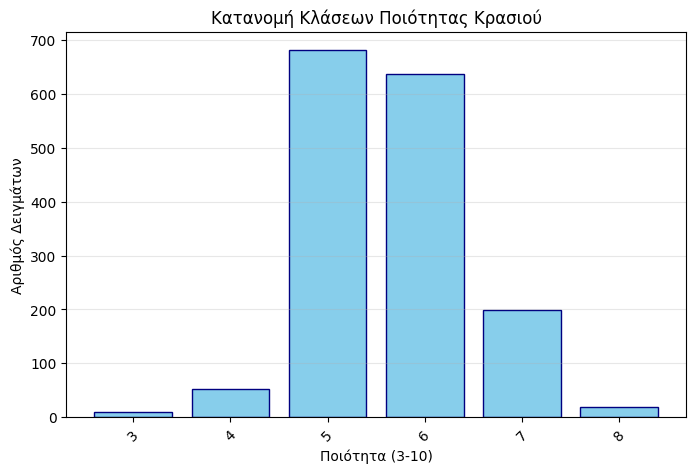


Στατιστικά Χαρακτηριστικών:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


In [3]:
# Κατανομή κλάσεων
LABEL_COL = 'quality'

print("EDA - Ανάλυση Dataset")
print(f"Διαστάσεις: {df.shape}")
print("\nΚατανομή Κλάσεων:")
class_counts = df[LABEL_COL].value_counts().sort_index()
print(class_counts)

# Plot κατανομής κλάσεων
plt.figure(figsize=(8,5))
plt.bar(class_counts.index.astype(str), class_counts.values, color='skyblue', edgecolor='navy')
plt.title('Κατανομή Κλάσεων Ποιότητας Κρασιού')
plt.xlabel('Ποιότητα (3-10)')
plt.ylabel('Αριθμός Δειγμάτων')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.show()

# Στατιστικά χαρακτηριστικών
print("\nΣτατιστικά Χαρακτηριστικών:")
features_stats = df.describe(include=np.number)
display((features_stats).T)



## Προεπεξεργασία Δεδομένων

**Βήματα**:
1. **Φιλτράρισμα**: quality = 5,6,7 (3 κλάσεις για multiclass)
2. **Label Encoding**: 5→0, 6→1, 7→2
3. **Features/Labels**: X (11 features), y (encoded labels)
4. **Train/Test Split**: 70/30 με stratify
5. **StandardScaler**: Κανονικοποίηση

In [ ]:
# Προεπεξεργασία - Filtering & Encoding
def prepare_features_and_labels(df, label_col):
    # Φιλτράρισμα μόνο κλάσεις 5,6,7
    df_filtered = df[df[label_col].isin([5,6,7])].copy()
    print(f"Φιλτράρισμα: {len(df_filtered)} δείγματα (5,6,7)")

    X_df = df_filtered.drop(columns=label_col).select_dtypes(include=np.number)
    y = df_filtered[label_col]

    print(f"Features: {X_df.shape[1]}")
    return X_df.to_numpy(dtype=float), y.to_numpy()

def encode_labels(y):
    """Label encoding: 5→0, 6→1, 7→2"""
    unique_labels = np.unique(y)
    label_to_id = {lab: i for i, lab in enumerate(unique_labels)}
    id_to_label = {i: lab for lab, i in label_to_id.items()}

    y_encoded = np.array([label_to_id[lab] for lab in y], dtype=int)

    print("Label Encoding:")
    for lab, i in label_to_id.items():
        print(f"   {lab} → {i}")

    return y_encoded, label_to_id, id_to_label

X, y_raw = prepare_features_and_labels(df, LABEL_COL)
y, label_to_id, id_to_label = encode_labels(y_raw)

print(f"\nX: {X.shape}, y: {y.shape} (K={np.max(y)+1} κλάσεις)")


Φιλτράρισμα: 1518 δείγματα (5,6,7)
Features: 11
Label Encoding:
   5 → 0
   6 → 1
   7 → 2

X: (1518, 11), y: (1518,) (K=3 κλάσεις)


In [5]:
# Train/Test Split (70/30 με stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f"Split: Train {X_train.shape[0]}, Test {X_test.shape[0]}")

# StandardScaler
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print(f"Scaling: X_train_sc {X_train_sc.shape}, X_test_sc {X_test_sc.shape}")
print("\nΠαράδειγμα scaled features (πρώτες 3 γραμμές):")
print(X_train_sc[:3])

K = int(np.max(y_train) + 1)
print(f"\nK={K} κλάσεις")


Split: Train 1062, Test 456
Scaling: X_train_sc (1062, 11), X_test_sc (456, 11)

Παράδειγμα scaled features (πρώτες 3 γραμμές):
[[-1.1239448   2.16255442 -1.42256323 -0.16752546  1.55772986 -0.98937495
  -1.1103729  -0.67978834  1.70523867 -0.88333667  0.38158601]
 [ 1.42902489 -0.29646236  0.80036219 -0.31566204  1.6585409   1.01480691
   0.59707776  0.76656616 -0.90779086  0.5482705   0.38158601]
 [ 0.32660616  0.41457864  1.16223377 -0.38973033  5.00546731  1.01480691
   1.07136961 -0.20125469 -1.77880071  5.41573486 -0.86262021]]

K=3 κλάσεις


# Υλοποίηση Αλγορίθμων

## PCA (Principal Component Analysis)

**Σκοπός**: Μείωση διαστάσεων από D=11 → M=2,3 για visualization  
**Μέθοδος**: Eigenvalue decomposition του covariance matrix  
**Επιλογή M**: Βάσει explained variance ratio (~80-90%)


In [ ]:
# PCA class
class myPCA:
    def __init__(self, M: int):
        self.M = M
        self.U = None  # Eigenvectors
        self.lambdas = None  # Eigenvalues
        self.mu = None  # Mean

    def fit(self, X: np.ndarray):
        """PCA fit: Z = U^T (X - μ)"""
        self.mu = X.mean(axis=0)
        Xc = X - self.mu  # Centering
        S = Xc.T @ Xc / Xc.shape[0]  # Covariance matrix

        eigvals, eigvecs = np.linalg.eigh(S)
        order = np.argsort(eigvals)[::-1]  # Descending order
        eigvals = eigvals[order]
        eigvecs = eigvecs[:, order]

        self.lambdas = eigvals[:self.M]
        self.U = eigvecs[:, :self.M]
        Z = Xc @ self.U

        print(f"PCA fit: X {X.shape} → Z {Z.shape}")
        return Z

    def transform(self, X: np.ndarray):
        """Transform new data"""
        Xc = X - self.mu
        return Xc @ self.U

# Full eigenvalues για explained variance
def pca_full_eigenvalues(X: np.ndarray):
    Xc = X - np.mean(X, axis=0)
    S = Xc.T @ Xc / Xc.shape[0]
    eigvals, _ = np.linalg.eigh(S)
    return np.sort(eigvals)[::-1]

print("PCA class ορισμένη!")


PCA class ορισμένη!


Explained Variance Ratio:
  PC1: 0.278 (Σωρευτικό: 0.278)
  PC2: 0.179 (Σωρευτικό: 0.457)
  PC3: 0.137 (Σωρευτικό: 0.594)
  PC4: 0.113 (Σωρευτικό: 0.707)
  PC5: 0.086 (Σωρευτικό: 0.793)


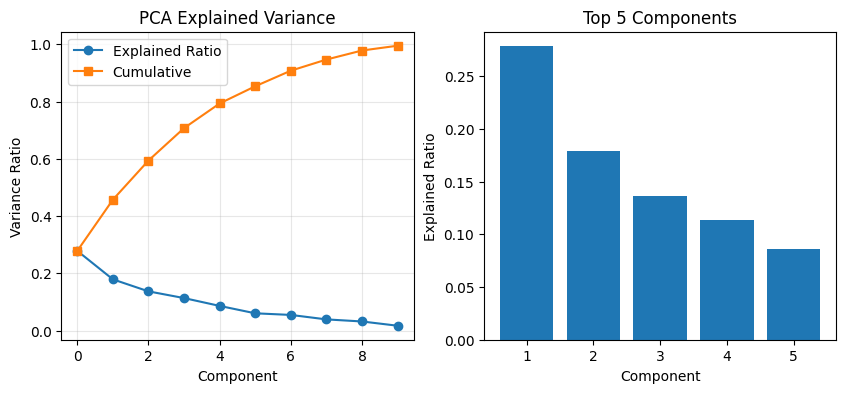

PCA fit: X (1062, 11) → Z (1062, 3)

PCA M=3: Z_train (1062, 3), Z_test (456, 3)
   Explained variance: 0.594


In [7]:
# PCA Analysis & Visualization
# PCA Explained Variance Analysis
eigvals = pca_full_eigenvalues(X_train_sc)
explained_ratio = eigvals / np.sum(eigvals)
cumulative_ratio = np.cumsum(explained_ratio)

print("Explained Variance Ratio:")
for i, (ratio, cum) in enumerate(zip(explained_ratio[:5], cumulative_ratio[:5]), 1):
    print(f"  PC{i}: {ratio:.3f} (Σωρευτικό: {cum:.3f})")

# Plot Explained Variance
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(explained_ratio[:10], 'o-', label='Explained Ratio')
plt.plot(cumulative_ratio[:10], 's-', label='Cumulative')
plt.xlabel('Component')
plt.ylabel('Variance Ratio')
plt.title('PCA Explained Variance')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1,2,2)
plt.bar(range(1,6), explained_ratio[:5])
plt.xlabel('Component')
plt.ylabel('Explained Ratio')
plt.title('Top 5 Components')
plt.show()

# Επιλογή M=3 (~80-90% variance)
M = 3
pca = myPCA(M)
Z_train = pca.fit(X_train_sc)
Z_test = pca.transform(X_test_sc)

print(f"\nPCA M={M}: Z_train {Z_train.shape}, Z_test {Z_test.shape}")
print(f"   Explained variance: {np.sum(pca.lambdas)/np.sum(eigvals):.3f}")


Οπτικοποίηση PCA (Train set):


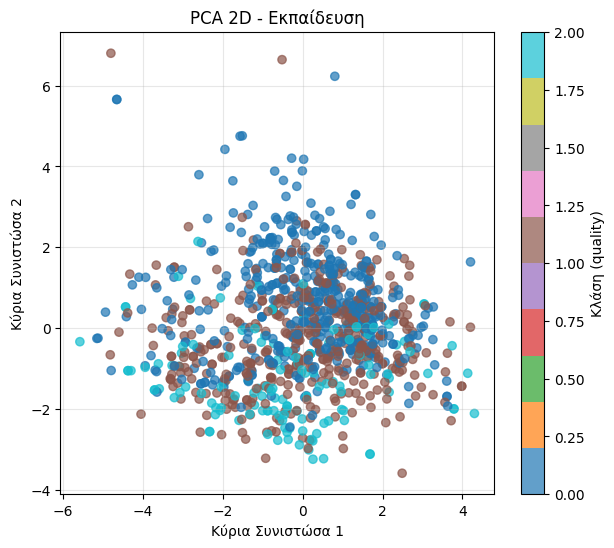

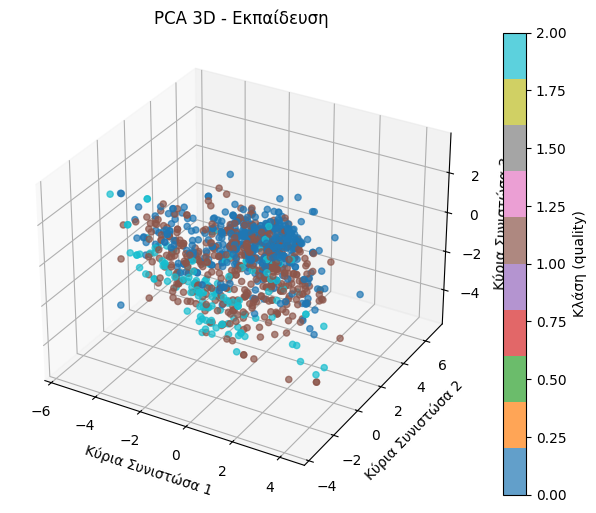

In [ ]:
from mpl_toolkits.mplot3d import Axes3D  # για 3D plot

def plot_pca_scatter(Z, y, M, title_prefix="PCA"):
    """Οπτικοποίηση PCA σε 2D ή 3D"""
    if M >= 2:
        plt.figure(figsize=(7,6))
        scatter = plt.scatter(Z[:,0], Z[:,1], c=y, cmap='tab10', alpha=0.7)
        plt.xlabel('Κύρια Συνιστώσα 1')
        plt.ylabel('Κύρια Συνιστώσα 2')
        plt.title(f'{title_prefix} 2D - Εκπαίδευση')
        plt.colorbar(scatter, label='Κλάση (quality)')
        plt.grid(True, alpha=0.3)
        plt.show()

    if M >= 3:
        fig = plt.figure(figsize=(8,6))
        ax = fig.add_subplot(111, projection='3d')
        p = ax.scatter(Z[:,0], Z[:,1], Z[:,2], c=y, cmap='tab10', alpha=0.7)
        ax.set_xlabel('Κύρια Συνιστώσα 1')
        ax.set_ylabel('Κύρια Συνιστώσα 2')
        ax.set_zlabel('Κύρια Συνιστώσα 3')
        ax.set_title(f'{title_prefix} 3D - Εκπαίδευση')
        fig.colorbar(p, label='Κλάση (quality)')
        plt.show()

print("Οπτικοποίηση PCA (Train set):")
plot_pca_scatter(Z_train, y_train, M)


## Βοηθητικές Συναρτήσεις Αξιολόγησης

Στην ενότητα αυτή ορίζονται βοηθητικές συναρτήσεις που
χρησιμοποιούνται για την αξιολόγηση όλων των μοντέλων
(accuracy και confusion matrix).

In [ ]:
# Helpers - Accuracy & Confusion Matrix
def my_accuracy(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.mean(y_true == y_pred))

def my_confusion_matrix(y_true: np.ndarray, y_pred: np.ndarray, K: int):
    cm = np.zeros((K, K), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[int(t), int(p)] += 1
    return cm

# Λεκτικές ετικέτες για τις κλάσεις
pretty_labels = {
    5: "καλή",
    6: "πολύ καλή",
    7: "άριστη"
}

# Μετατροπή id_to_label (0,1,2) -> λεκτικό
id_to_pretty = {i: pretty_labels[lab] for i, lab in id_to_label.items()}
id_to_pretty



def my_plot_confusion_matrix(cm: np.ndarray, id_to_label: dict):
    """Οπτικοποίηση confusion matrix με λεκτικές ετικέτες"""
    labels = [id_to_label[i] for i in range(cm.shape[0])]
    plt.figure(figsize=(6,5))
    im = plt.imshow(cm, cmap='Blues')

    plt.title('Confusion Matrix')
    plt.xticks(range(len(labels)), labels, rotation=45, ha='right')
    plt.yticks(range(len(labels)), labels)
    plt.xlabel('Προβλεπόμενη Κλάση')
    plt.ylabel('Πραγματική Κλάση')

    cbar = plt.colorbar(im)
    cbar.set_label('Πλήθος δειγμάτων')

    # Μαύροι αριθμοί
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, str(cm[i, j]),
                     ha='center', va='center', color='black')

    plt.tight_layout()
    plt.show()

print("Helpers OK")


Helpers OK


## Least Squares

**Μέθοδος**:
- One-vs-Rest: K regressors (Y_{i,k} = 1 αν y_i=k, αλλιώς 0)
- Λύση: W = (X^T X + λI)^(-1) X^T Y (ridge regression)
- Πρόβλεψη: argmax_k (X W)_k [file:8]

**Features**: PCA Z_train (M=3) ή scaled features


In [10]:
# Υλοποίηση Least Squares
def one_vs_rest_targets(y: np.ndarray, K: int) -> np.ndarray:
    """One-vs-Rest targets: Y_{N,K}"""
    N = y.shape[0]
    Y = np.zeros((N, K), dtype=float)
    Y[np.arange(N), y.astype(int)] = 1.0
    return Y

class myLeastSquaresOVR:
    def __init__(self, lam: float = 1e-3, add_bias: bool = True):
        self.lam = lam  # L2 ridge
        self.add_bias = add_bias
        self.W = None  # (D+1, K)

    def _add_bias(self, X: np.ndarray) -> np.ndarray:
        if not self.add_bias:
            return X
        return np.hstack([np.ones((X.shape[0], 1)), X])

    def fit(self, X: np.ndarray, y: np.ndarray):
        Xb = self._add_bias(X)  # N x (D+1)
        N, D1 = Xb.shape
        K = int(np.max(y) + 1)
        Y = one_vs_rest_targets(y, K)  # N x K

        XtX = Xb.T @ Xb
        I = np.eye(D1)
        if self.add_bias:
            I[0, 0] = 0.0  # No regularization on bias

        A = XtX + self.lam * I
        B = Xb.T @ Y
        self.W = np.linalg.solve(A, B)

        print(f"Least Squares fit: W shape {self.W.shape}")

    def predict_scores(self, X: np.ndarray) -> np.ndarray:
        Xb = self._add_bias(X)
        return Xb @ self.W  # N x K

    def predict(self, X: np.ndarray) -> np.ndarray:
        scores = self.predict_scores(X)
        return np.argmax(scores, axis=1)

print("Least Squares OK!")


Least Squares OK!


Least Squares με Scaled Features
Features: (1062, 11), K=3
Least Squares fit: W shape (12, 3)

Least Squares Αποτελέσματα:
  Accuracy Train: 0.6243
  Accuracy Test:  0.5855

Confusion Matrix (Test):
[[156  48   0]
 [ 81 111   0]
 [  5  55   0]]


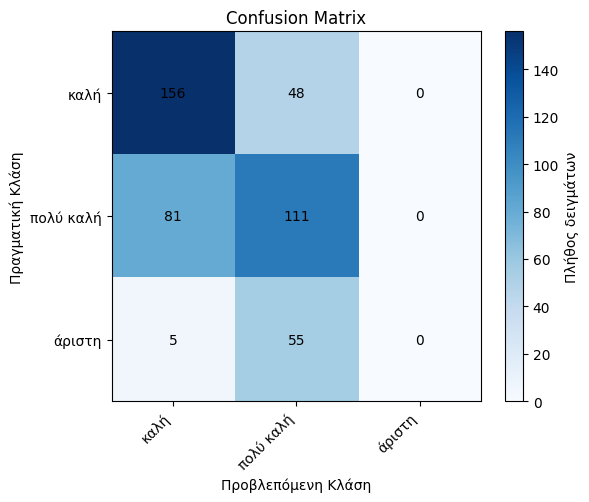

In [11]:
# Εκπαίδευση + Αξιολόγηση
# Επιλογή features: PCA ή Scaled
USE_PCA = False
if USE_PCA:
    X_tr, X_te = Z_train, Z_test
    print("Least Squares με PCA (Z_train)")
else:
    X_tr, X_te = X_train_sc, X_test_sc
    print("Least Squares με Scaled Features")

y_tr, y_te = y_train, y_test
print(f"Features: {X_tr.shape}, K={K}")

# Εκπαίδευση
lam = 1e-3
ls = myLeastSquaresOVR(lam=lam, add_bias=True)
ls.fit(X_tr, y_tr)

# Πρόβλεψη
y_tr_pred = ls.predict(X_tr)
y_te_pred = ls.predict(X_te)

# Accuracy
train_acc = my_accuracy(y_tr, y_tr_pred)
test_acc = my_accuracy(y_te, y_te_pred)

print(f"\nLeast Squares Αποτελέσματα:")
print(f"  Accuracy Train: {train_acc:.4f}")
print(f"  Accuracy Test:  {test_acc:.4f}")

# Confusion Matrix
cm = my_confusion_matrix(y_te, y_te_pred, K)
print("\nConfusion Matrix (Test):")
print(cm)

my_plot_confusion_matrix(cm, id_to_pretty)


## Logistic Regression (Softmax + SGD)

**Στόχος**: Βελτίωση της απόδοσης σε σχέση με Least Squares, με μοντέλο κατάλληλο για ταξινόμηση.

**Μέθοδος**:
- Πολυταξική Logistic Regression με **Softmax** έξοδο
- **Loss**: Cross-Entropy (Softmax Cross-Entropy)
- **Βελτιστοποίηση**: Stochastic / Mini-batch Gradient Descent

**Πρόβλεψη**:  
Για κάθε δείγμα \(x\), το μοντέλο υπολογίζει scores \(s_k = w_k^T x\) για κάθε κλάση \(k\).  
Μετά εφαρμόζει Softmax ώστε να πάρουμε πιθανότητες κλάσεων και επιλέγουμε την κλάση με τη μέγιστη πιθανότητα.


In [12]:
# Softmax, One-hot, Cross-Entropy
def one_hot(y: np.ndarray, K: int) -> np.ndarray:
    """Μετατροπή labels σε one-hot πίνακα N x K"""
    N = y.shape[0]
    Y = np.zeros((N, K), dtype=float)
    Y[np.arange(N), y.astype(int)] = 1.0
    return Y

def softmax(logits: np.ndarray) -> np.ndarray:
    """Softmax σε κάθε σειρά (N x K) με αριθμητική σταθερότητα"""
    z = logits - np.max(logits, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

def cross_entropy(probs: np.ndarray, y: np.ndarray) -> float:
    """Cross-Entropy Loss για labels y (όχι one-hot)"""
    eps = 1e-12
    N = y.shape[0]
    p = probs[np.arange(N), y.astype(int)]
    return float(-np.mean(np.log(p + eps)))

print("Softmax, one-hot και Cross-Entropy ΟΚ.")


Softmax, one-hot και Cross-Entropy ΟΚ.


In [ ]:
# Υλοποίηση Logistic Regression
class myLogisticRegressionSoftmax:
    def __init__(self, lr: float = 0.1, epochs: int = 50,
                 batch_size: int = 64, lam: float = 0.0,
                 add_bias: bool = True, verbose: bool = True):
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.lam = lam          # L2 κανονικοποίηση
        self.add_bias = add_bias
        self.verbose = verbose

        self.W = None           # (D+1, K)
        self.loss_history = []

    def _add_bias(self, X: np.ndarray) -> np.ndarray:
        if not self.add_bias:
            return X
        return np.hstack([np.ones((X.shape[0], 1)), X])

    def fit(self, X: np.ndarray, y: np.ndarray):
        Xb = self._add_bias(X)          # N x (D+1)
        N, D1 = Xb.shape
        K = int(np.max(y) + 1)

        # Αρχικοποίηση βαρών
        self.W = 0.01 * np.random.randn(D1, K)
        self.loss_history = []

        indices = np.arange(N)

        for ep in range(1, self.epochs + 1):
            np.random.shuffle(indices)

            for start in range(0, N, self.batch_size):
                batch_idx = indices[start:start + self.batch_size]
                X_batch = Xb[batch_idx]
                y_batch = y[batch_idx]
                B = X_batch.shape[0]

                # Forward
                logits = X_batch @ self.W          # B x K
                probs = softmax(logits)            # B x K

                # One-hot targets
                Y_batch = one_hot(y_batch, K)      # B x K

                # Gradient (Softmax + Cross-Entropy)
                grad = X_batch.T @ (probs - Y_batch) / B   # D1 x K

                # L2 regularization (εκτός bias)
                if self.lam > 0:
                    reg = self.W.copy()
                    if self.add_bias:
                        reg[0, :] = 0.0
                    grad += self.lam * reg

                # Ενημέρωση βαρών
                self.W -= self.lr * grad

            # Υπολογισμός train loss στο τέλος epoch
            train_logits = Xb @ self.W
            train_probs = softmax(train_logits)
            loss = cross_entropy(train_probs, y)
            self.loss_history.append(loss)

            if self.verbose and (ep == 1 or ep % 10 == 0 or ep == self.epochs):
                print(f"Epoch {ep:03d}/{self.epochs} - Loss: {loss:.4f}")

        print("Η Εκπαίδευση Logistic Regression ολοκληρώθηκε.")

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        Xb = self._add_bias(X)
        logits = Xb @ self.W
        return softmax(logits)

    def predict(self, X: np.ndarray) -> np.ndarray:
        probs = self.predict_proba(X)
        return np.argmax(probs, axis=1)


Logistic Regression με PCA (Z_train)
Features: (1062, 3), K=3
Epoch 001/80 - Loss: 0.8650
Epoch 010/80 - Loss: 0.8076
Epoch 020/80 - Loss: 0.8069
Epoch 030/80 - Loss: 0.8108
Epoch 040/80 - Loss: 0.8076
Epoch 050/80 - Loss: 0.8068
Epoch 060/80 - Loss: 0.8073
Epoch 070/80 - Loss: 0.8091
Epoch 080/80 - Loss: 0.8067
Η Εκπαίδευση Logistic Regression ολοκληρώθηκε.

Logistic Regression Αποτελέσματα:
  Accuracy Train: 0.6017
  Accuracy Test:  0.6053


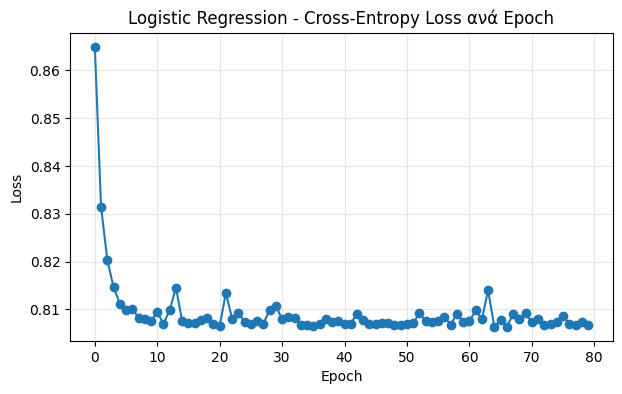


Confusio Matrix (Test):
[[145  57   2]
 [ 67 119   6]
 [  3  45  12]]


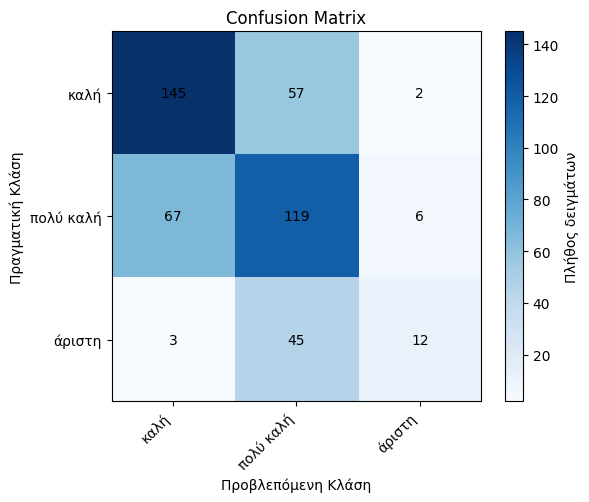

In [14]:
# Εκπαίδευση & Αξιολόγηση Logistic Regression
# Επιλογή features: PCA ή Scaled
USE_PCA = True
if USE_PCA:
    X_tr, X_te = Z_train, Z_test
    print("Logistic Regression με PCA (Z_train)")
else:
    X_tr, X_te = X_train_sc, X_test_sc
    print("Logistic Regression με Scaled Features")

y_tr, y_te = y_train, y_test
print(f"Features: {X_tr.shape}, K={K}")

# Υπερπαράμετροι
lr = 0.2
epochs = 80
batch_size = 64
lam = 1e-3

logreg = myLogisticRegressionSoftmax(
    lr=lr,
    epochs=epochs,
    batch_size=batch_size,
    lam=lam,
    add_bias=True,
    verbose=True
)

# Εκπαίδευση
logreg.fit(X_tr, y_tr)

# Πρόβλεψη
y_tr_pred = logreg.predict(X_tr)
y_te_pred = logreg.predict(X_te)

# Accuracy
train_acc = my_accuracy(y_tr, y_tr_pred)
test_acc = my_accuracy(y_te, y_te_pred)

print(f"\nLogistic Regression Αποτελέσματα:")
print(f"  Accuracy Train: {train_acc:.4f}")
print(f"  Accuracy Test:  {test_acc:.4f}")

# Plot Loss ανά epoch
plt.figure(figsize=(7,4))
plt.plot(logreg.loss_history, marker='o')
plt.title('Logistic Regression - Cross-Entropy Loss ανά Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.show()

# Confusion Matrix με λεκτικές ετικέτες
cm = my_confusion_matrix(y_te, y_te_pred, K)
print("\nConfusio Matrix (Test):")
print(cm)
my_plot_confusion_matrix(cm, id_to_pretty)


## k-Πλησιέστεροι Γείτονες- K Nearest Neighbors(kNN)

**Ιδέα**:
- Για κάθε νέο δείγμα, βρίσκουμε τους **k πιο κοντινούς γείτονες** στο train set (π.χ. με ευκλείδεια απόσταση).
- Η κλάση αποφασίζεται με **πλειοψηφία** (majority vote) των labels των γειτόνων.

**Χαρακτηριστικά**:
- Απλός, μη παραμετρικός αλγόριθμος.
- Η απόδοση εξαρτάται έντονα από:
  - την τιμή του **k**
  - την **κλιμάκωση** των χαρακτηριστικών (γι’ αυτό χρησιμοποιούμε StandardScaler).


In [15]:
# Υλοποίηση kNN
def euclidean_distances(X1: np.ndarray, X2: np.ndarray) -> np.ndarray:
    """Υπολογισμός ευκλείδειων αποστάσεων ανάμεσα σε όλα τα ζεύγη δειγμάτων"""
    # X1: N1 x D, X2: N2 x D  →  distances: N1 x N2
    X1_sq = np.sum(X1**2, axis=1, keepdims=True)      # N1 x 1
    X2_sq = np.sum(X2**2, axis=1, keepdims=True).T    # 1 x N2
    cross = X1 @ X2.T                                 # N1 x N2
    dists = np.sqrt(np.maximum(X1_sq + X2_sq - 2*cross, 0.0))
    return dists

def my_knn_predict(X_train: np.ndarray, y_train: np.ndarray,
                   X_test: np.ndarray, k: int) -> np.ndarray:
    """kNN πρόβλεψη για όλα τα δείγματα του X_test"""
    dists = euclidean_distances(X_test, X_train)   # N_test x N_train
    N_test = X_test.shape[0]
    y_pred = np.zeros(N_test, dtype=int)

    for i in range(N_test):
        # indices των k κοντινότερων γειτόνων
        nn_idx = np.argsort(dists[i])[:k]
        nn_labels = y_train[nn_idx]
        # πλειοψηφία
        values, counts = np.unique(nn_labels, return_counts=True)
        y_pred[i] = values[np.argmax(counts)]
    return y_pred

print("kNN helper συναρτήσεις ΟΚ")


kNN helper συναρτήσεις ΟΚ


kNN με PCA (Z_train)
Features: (1062, 3), K=3
Δοκιμή διαφόρων τιμών k:
  k =  1  →  Test Accuracy = 0.6360
  k =  3  →  Test Accuracy = 0.5899
  k =  5  →  Test Accuracy = 0.5768
  k =  7  →  Test Accuracy = 0.5811
  k =  9  →  Test Accuracy = 0.5636
  k = 11  →  Test Accuracy = 0.5636
  k = 13  →  Test Accuracy = 0.5636
  k = 15  →  Test Accuracy = 0.5855
  k = 17  →  Test Accuracy = 0.5680
  k = 19  →  Test Accuracy = 0.5702
  k = 21  →  Test Accuracy = 0.5746
  k = 23  →  Test Accuracy = 0.5789
  k = 25  →  Test Accuracy = 0.5768

Καλύτερο k = 1 με Test Accuracy = 0.6360


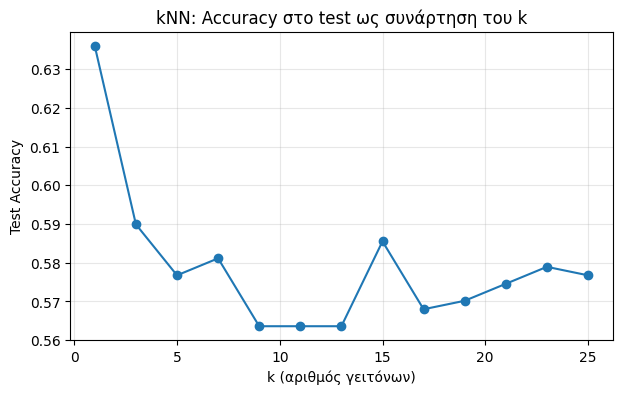


Τελικά Αποτελέσματα kNN (k=1):
  Accuracy Train: 1.0000
  Accuracy Test:  0.6360

Confusio Matrix (Test):
[[145  51   8]
 [ 49 118  25]
 [  8  25  27]]


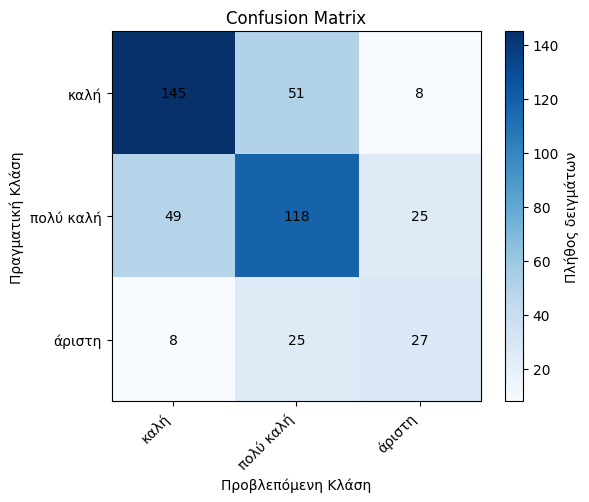

In [16]:
# kNN – Sweep σε k, Αποτελέσματα & Confusion Matrix
# Επιλογή features: PCA ή Scaled
USE_PCA = True
if USE_PCA:
    X_tr, X_te = Z_train, Z_test
    print("kNN με PCA (Z_train)")
else:
    X_tr, X_te = X_train_sc, X_test_sc
    print("kNN με Scaled Features")

y_tr, y_te = y_train, y_test
print(f"Features: {X_tr.shape}, K={K}")

# Τιμές του k για δοκιμή
k_values = list(range(1, 26, 2))   # 1,3,5,...,25
test_accs = []

print("Δοκιμή διαφόρων τιμών k:")
for k in k_values:
    y_te_pred_k = my_knn_predict(X_tr, y_tr, X_te, k)
    acc_k = my_accuracy(y_te, y_te_pred_k)
    test_accs.append(acc_k)
    print(f"  k = {k:2d}  →  Test Accuracy = {acc_k:.4f}")

# Επιλογή καλύτερου k
best_idx = int(np.argmax(test_accs))
best_k = k_values[best_idx]
best_acc = test_accs[best_idx]
print(f"\nΚαλύτερο k = {best_k} με Test Accuracy = {best_acc:.4f}")

# Plot Test Accuracy vs k
plt.figure(figsize=(7,4))
plt.plot(k_values, test_accs, marker='o')
plt.title('kNN: Accuracy στο test ως συνάρτηση του k')
plt.xlabel('k (αριθμός γειτόνων)')
plt.ylabel('Test Accuracy')
plt.grid(True, alpha=0.3)
plt.show()

# Τελική εκπαίδευση/πρόβλεψη με best_k
y_tr_pred = my_knn_predict(X_tr, y_tr, X_tr, best_k)
y_te_pred = my_knn_predict(X_tr, y_tr, X_te, best_k)

train_acc = my_accuracy(y_tr, y_tr_pred)
test_acc = my_accuracy(y_te, y_te_pred)

print(f"\nΤελικά Αποτελέσματα kNN (k={best_k}):")
print(f"  Accuracy Train: {train_acc:.4f}")
print(f"  Accuracy Test:  {test_acc:.4f}")

# Confusion Matrix με λεκτικές ετικέτες
cm = my_confusion_matrix(y_te, y_te_pred, K)
print("\nConfusio Matrix (Test):")
print(cm)
my_plot_confusion_matrix(cm, id_to_pretty)


## Naive Bayes

**Ιδέα**:
- Υπολογίζουμε για κάθε κλάση:
  - **Μέση τιμή** και **διακύμανση** για κάθε χαρακτηριστικό.
  - **Πιθανότητα κλάσης** \(P(y=k)\).
- Υποθέτουμε ότι τα χαρακτηριστικά, δοθέντος του y, είναι **ανεξάρτητα** και ακολουθούν **κανονική κατανομή** (Gaussian).

**Πρόβλεψη**:
- Υπολογίζουμε το log-posterior \(\log P(y=k \mid x)\) για κάθε κλάση.
- Επιλέγουμε την κλάση με το μεγαλύτερο log-posterior.

Ο Naive Bayes είναι απλός, γρήγορος και συχνά αποδίδει καλά, ακόμη και όταν η υπόθεση ανεξαρτησίας δεν ισχύει πλήρως.


In [ ]:
# Υλοποίηση Naive Bayes
class myGaussianNaiveBayes:
    def __init__(self, eps: float = 1e-9):
        self.eps = eps
        self.means = None   # K x D
        self.vars = None    # K x D
        self.priors = None  # K
        self.K = None

    def fit(self, X: np.ndarray, y: np.ndarray):
        self.K = int(np.max(y) + 1)
        N, D = X.shape

        self.means = np.zeros((self.K, D))
        self.vars = np.zeros((self.K, D))
        self.priors = np.zeros(self.K)

        for k in range(self.K):
            Xk = X[y == k]           # Nk x D
            self.means[k] = Xk.mean(axis=0)
            self.vars[k] = Xk.var(axis=0) + self.eps
            self.priors[k] = Xk.shape[0] / N

        print("Gaussian Naive Bayes εκπαιδεύτηκε.")

    def _log_gaussian_pdf(self, X: np.ndarray, mean: np.ndarray, var: np.ndarray):
        """
        X: N x D, mean/var: D
        Επιστρέφει log-πιθανότητες για κάθε δείγμα (μήκος N).
        """
        # Βεβαιώσου ότι το X είναι 2D
        X = np.atleast_2d(X)          
        D = X.shape[1]
        return -0.5 * (
            np.log(2 * np.pi * var).sum() +
            ((X - mean) ** 2 / var).sum(axis=1)
        )

    def predict(self, X: np.ndarray) -> np.ndarray:
        X = np.atleast_2d(X)
        N = X.shape[0]
        log_post = np.zeros((N, self.K))

        for k in range(self.K):
            log_likelihood = self._log_gaussian_pdf(X, self.means[k], self.vars[k])
            log_prior = np.log(self.priors[k])
            log_post[:, k] = log_likelihood + log_prior

        return np.argmax(log_post, axis=1)


Naive Bayes με Scaled Features
Features: (1062, 11), K=3
Gaussian Naive Bayes εκπαιδεύτηκε.

Gaussian Naive Bayes Αποτελέσματα:
  Accuracy Train: 0.6130
  Accuracy Test:  0.5768

Confusion Matrix (Test):
[[137  55  12]
 [ 59  92  41]
 [  6  20  34]]


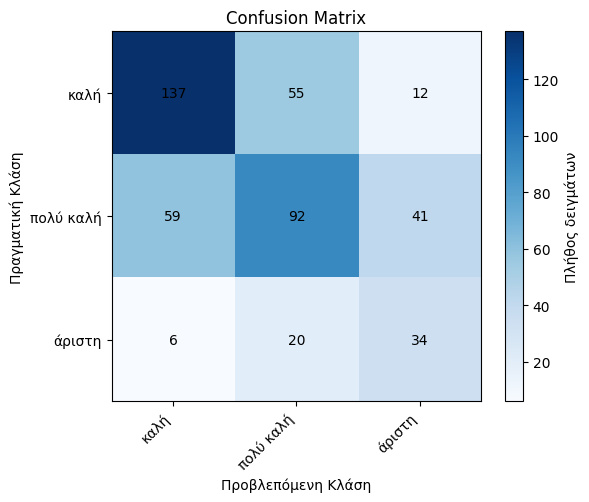

In [18]:
# Gaussian Naive Bayes – Εκπαίδευση & Αξιολόγηση
# Χρησιμοποιούμε τα κανονικοποιημένα features (όχι PCA εδώ συνήθως)
USE_PCA = False
if USE_PCA:
    X_tr, X_te = Z_train, Z_test
    print("Naive Bayes με PCA (Z_train)")
else:
    X_tr, X_te = X_train_sc, X_test_sc
    print("Naive Bayes με Scaled Features")

y_tr, y_te = y_train, y_test
print(f"Features: {X_tr.shape}, K={K}")

# Εκπαίδευση
nb = myGaussianNaiveBayes(eps=1e-9)
nb.fit(X_tr, y_tr)

# Πρόβλεψη
y_tr_pred = nb.predict(X_tr)
y_te_pred = nb.predict(X_te)

# Accuracy
train_acc = my_accuracy(y_tr, y_tr_pred)
test_acc = my_accuracy(y_te, y_te_pred)

print(f"\nGaussian Naive Bayes Αποτελέσματα:")
print(f"  Accuracy Train: {train_acc:.4f}")
print(f"  Accuracy Test:  {test_acc:.4f}")

# Confusion Matrix με λεκτικές ετικέτες
cm = my_confusion_matrix(y_te, y_te_pred, K)
print("\nConfusion Matrix (Test):")
print(cm)
my_plot_confusion_matrix(cm, id_to_pretty)


## Multilayer Perceptron (MLP) με PyTorch

**Στόχος**: Εκπαίδευση νευρωνικού δικτύου για πολυταξική ταξινόμηση ποιότητας κρασιού.

**Αρχιτεκτονική**:
- Είσοδος: D = 11 χαρακτηριστικά (scaled features)
- 1–2 κρυφά επίπεδα με ReLU
- Έξοδος: K = 3 κλάσεις (5, 6, 7)

**Εκπαίδευση**:
- Framework: PyTorch
- Loss: `CrossEntropyLoss` (συνδυάζει softmax + cross-entropy)
- Optimizer: `Adam`
- Mini-batch training, παρακολούθηση train/test loss και test accuracy ανά εποχή.

In [19]:
# Imports PyTorch & Device
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Συσκευή (GPU αν υπάρχει)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Συσκευή:", device)

# Θα χρησιμοποιήσουμε τα κανονικοποιημένα features (όχι PCA) για το MLP
X_tr_mlp = X_train_sc
X_te_mlp = X_test_sc
y_tr_mlp = y_train
y_te_mlp = y_test

print("X_tr_mlp:", X_tr_mlp.shape, "X_te_mlp:", X_te_mlp.shape)
print("Κλάσεις K =", K)


Συσκευή: cpu
X_tr_mlp: (1062, 11) X_te_mlp: (456, 11)
Κλάσεις K = 3


In [20]:
# DataLoaders & Μοντέλο MLP
# Μετατροπή numpy → torch tensors
X_tr_tensor = torch.from_numpy(X_tr_mlp).float()
y_tr_tensor = torch.from_numpy(y_tr_mlp).long()
X_te_tensor = torch.from_numpy(X_te_mlp).float()
y_te_tensor = torch.from_numpy(y_te_mlp).long()

# TensorDatasets & DataLoaders
batch_size = 64

train_ds = TensorDataset(X_tr_tensor, y_tr_tensor)
test_ds  = TensorDataset(X_te_tensor, y_te_tensor)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

print("DataLoaders ΟΚ!")


# Ορισμός MLP
class MLP(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, num_classes: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        return self.net(x)


D = X_tr_mlp.shape[1]
hidden_dim = 32
mlp = MLP(input_dim=D, hidden_dim=hidden_dim, num_classes=K).to(device)
print(mlp)


DataLoaders ΟΚ!
MLP(
  (net): Sequential(
    (0): Linear(in_features=11, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=3, bias=True)
  )
)


Epoch 001/50 - Train Loss: 1.0826  |  Test Loss: 1.0417  |  Test Acc: 0.4803
Epoch 010/50 - Train Loss: 0.7574  |  Test Loss: 0.8086  |  Test Acc: 0.6096
Epoch 020/50 - Train Loss: 0.7198  |  Test Loss: 0.8079  |  Test Acc: 0.6250
Epoch 030/50 - Train Loss: 0.6970  |  Test Loss: 0.8048  |  Test Acc: 0.6338
Epoch 040/50 - Train Loss: 0.6770  |  Test Loss: 0.8118  |  Test Acc: 0.6404
Epoch 050/50 - Train Loss: 0.6569  |  Test Loss: 0.8121  |  Test Acc: 0.6382
Εκπαίδευση MLP ολοκληρώθηκε!

Τελική Test Accuracy: 0.6382


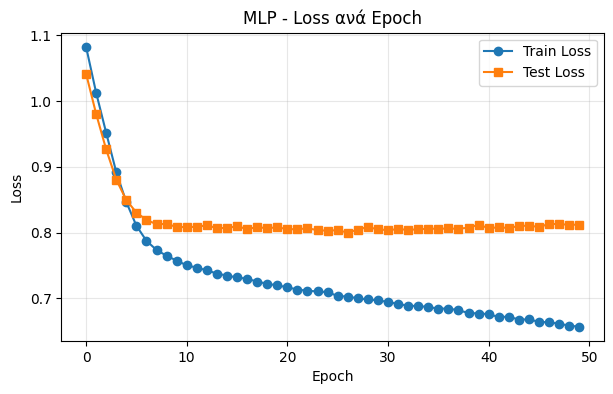

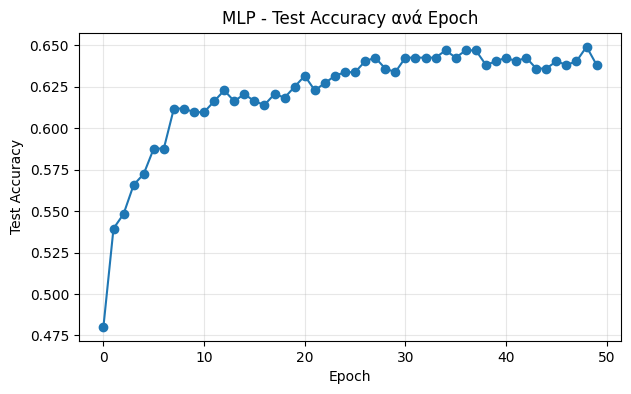


Confusion Matrix (Test):
[[146  56   2]
 [ 60 124   8]
 [  4  35  21]]


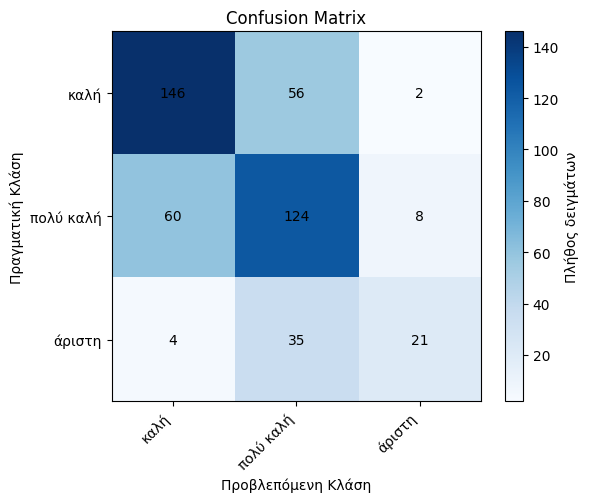

In [ ]:
# Εκπαίδευση MLP & Αξιολόγηση

# Loss & Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3)

num_epochs = 50

train_losses = []
test_losses = []
test_accs = []

for epoch in range(1, num_epochs + 1):
    # Εκπαίδευση 
    mlp.train()
    epoch_train_loss = 0.0
    total_train = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        outputs = mlp(X_batch)              # logits
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        batch_size_curr = y_batch.size(0)
        epoch_train_loss += loss.item() * batch_size_curr
        total_train += batch_size_curr

    epoch_train_loss /= total_train
    train_losses.append(epoch_train_loss)

    # Αξιολόγηση στο test set
    mlp.eval()
    epoch_test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = mlp(X_batch)
            loss = criterion(outputs, y_batch)

            epoch_test_loss += loss.item() * y_batch.size(0)
            total += y_batch.size(0)

            preds = outputs.argmax(dim=1)
            correct += (preds == y_batch).sum().item()

    epoch_test_loss /= total
    test_losses.append(epoch_test_loss)
    test_acc = correct / total
    test_accs.append(epoch_test_acc := test_acc)

    if epoch == 1 or epoch % 10 == 0 or epoch == num_epochs:
        print(f"Epoch {epoch:03d}/{num_epochs} - "
              f"Train Loss: {epoch_train_loss:.4f}  |  "
              f"Test Loss: {epoch_test_loss:.4f}  |  "
              f"Test Acc: {epoch_test_acc:.4f}")

print("Εκπαίδευση MLP ολοκληρώθηκε!")

# Τελική ακρίβεια
print(f"\nΤελική Test Accuracy: {test_accs[-1]:.4f}")

# Διαγράμματα Loss & Accuracy
plt.figure(figsize=(7,4))
plt.plot(train_losses, 'o-', label='Train Loss')
plt.plot(test_losses, 's-', label='Test Loss')
plt.title('MLP - Loss ανά Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(test_accs, 'o-')
plt.title('MLP - Test Accuracy ανά Epoch')
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy')
plt.grid(True, alpha=0.3)
plt.show()

# Confusion Matrix στο test set
mlp.eval()
with torch.no_grad():
    outputs = mlp(X_te_tensor.to(device))
    preds_te = outputs.argmax(dim=1).cpu().numpy()

cm = my_confusion_matrix(y_te_mlp, preds_te, K)
print("\nConfusion Matrix (Test):")
print(cm)
my_plot_confusion_matrix(cm, id_to_pretty)


## Support Vector Machines (SVM) – One-vs-Rest

**Ιδέα**:
- Γραμμικά SVMs για **binary** ταξινόμηση με **hinge loss**.
- Για K κλάσεις χρησιμοποιούμε στρατηγική **One-vs-Rest**:
  - Εκπαιδεύουμε K γραμμικά SVMs, ένα για κάθε κλάση (k vs all).
  - Για ένα δείγμα x, υπολογίζουμε τα scores από όλα τα SVMs και επιλέγουμε την κλάση με το μεγαλύτερο score.

**Loss (για κάθε binary SVM)**:
- Hinge loss: \( L = \max(0, 1 - y (w^T x + b)) \) με \(y \in \{-1, +1\}\).
- Soft-margin SVM με **L2 κανονικοποίηση** στα βάρη.


In [ ]:
# Γραμμικό SVM & One-vs-Rest
class BinaryLinearSVM:
    """
    Γραμμικό SVM για binary ταξινόμηση με hinge loss και L2 κανονικοποίηση.
    y ∈ {−1, +1}
    """
    def __init__(self, C: float = 1.0, lr: float = 1e-3, epochs: int = 100):
        self.C = C          # trade-off between margin & hinge loss
        self.lr = lr
        self.epochs = epochs
        self.w = None       
        self.b = 0.0

    def fit(self, X: np.ndarray, y: np.ndarray):
        N, D = X.shape
        # y πρέπει να είναι -1 ή +1
        y = y.astype(float)
        self.w = np.zeros(D, dtype=float)
        self.b = 0.0

        for ep in range(1, self.epochs + 1):
            # SGD πάνω σε κάθε δείγμα
            for i in range(N):
                xi = X[i]
                yi = y[i]
                margin = yi * (np.dot(self.w, xi) + self.b)

                if margin < 1:
                    # gradient για hinge loss + L2
                    self.w = self.w - self.lr * (self.w - self.C * yi * xi)
                    self.b = self.b + self.lr * self.C * yi
                else:
                    # μόνο L2 στα w
                    self.w = self.w - self.lr * self.w

        # Δεν εκτυπώνουμε ανά epoch

    def decision_function(self, X: np.ndarray) -> np.ndarray:
        return X @ self.w + self.b

    def predict(self, X: np.ndarray) -> np.ndarray:
        scores = self.decision_function(X)
        return np.where(scores >= 0, 1, -1)


class OneVsRestSVM:
    """
    One-vs-Rest SVM για K κλάσεις:
    - K binary SVMs, ένα για κάθε κλάση k vs all.
    - Πρόβλεψη: argmax_k score_k(x)
    """
    def __init__(self, C: float = 1.0, lr: float = 1e-3, epochs: int = 50):
        self.C = C
        self.lr = lr
        self.epochs = epochs
        self.models = []
        self.K = None

    def fit(self, X: np.ndarray, y: np.ndarray):
        self.K = int(np.max(y) + 1)
        N, D = X.shape
        self.models = []

        for k in range(self.K):
            # labels: +1 για κλάση k, -1 για όλες τις άλλες
            yk = np.where(y == k, 1.0, -1.0)
            svm_k = BinaryLinearSVM(C=self.C, lr=self.lr, epochs=self.epochs)
            svm_k.fit(X, yk)
            self.models.append(svm_k)
            print(f"Εκπαιδεύτηκε SVM για κλάση {k}")

    def decision_function(self, X: np.ndarray) -> np.ndarray:
        # scores: N x K
        scores = np.column_stack([m.decision_function(X) for m in self.models])
        return scores

    def predict(self, X: np.ndarray) -> np.ndarray:
        scores = self.decision_function(X)
        return np.argmax(scores, axis=1)


SVM με Scaled Features
Features: (1062, 11), K=3
Εκπαιδεύτηκε SVM για κλάση 0
Εκπαιδεύτηκε SVM για κλάση 1
Εκπαιδεύτηκε SVM για κλάση 2

SVM One-vs-Rest Αποτελέσματα:
  Accuracy Train: 0.5904
  Accuracy Test:  0.5702

Confusion Matrix (Test):
[[172  23   9]
 [103  72  17]
 [  8  36  16]]


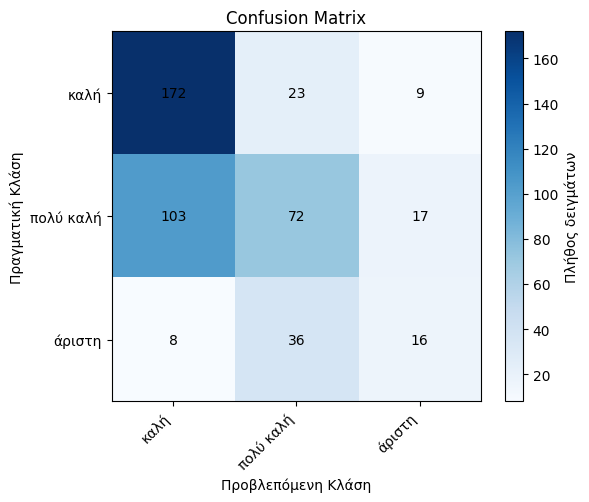

In [ ]:
# Εκπαίδευση & Αξιολόγηση SVM
# Χρησιμοποιούμε τα κανονικοποιημένα features
USE_PCA = False
if USE_PCA:
    X_tr, X_te = Z_train, Z_test
    print("SVM με PCA (Z_train)")
else:
    X_tr, X_te = X_train_sc, X_test_sc
    print("SVM με Scaled Features")

y_tr, y_te = y_train, y_test
print(f"Features: {X_tr.shape}, K={K}")

# Υπερπαράμετροι SVM
C = 10.0
lr = 1e-3
epochs = 1000

svm_ovr = OneVsRestSVM(C=C, lr=lr, epochs=epochs)
svm_ovr.fit(X_tr, y_tr)

# Πρόβλεψη
y_tr_pred = svm_ovr.predict(X_tr)
y_te_pred = svm_ovr.predict(X_te)

# Accuracy
train_acc = my_accuracy(y_tr, y_tr_pred)
test_acc = my_accuracy(y_te, y_te_pred)

print(f"\nSVM One-vs-Rest Αποτελέσματα:")
print(f"  Accuracy Train: {train_acc:.4f}")
print(f"  Accuracy Test:  {test_acc:.4f}")

# Confusion Matrix με λεκτικές ετικέτες
cm = my_confusion_matrix(y_te, y_te_pred, K)
print("\nConfusion Matrix (Test):")
print(cm)
my_plot_confusion_matrix(cm, id_to_pretty)


## K-Means

**Ιδέα**:
- Αλγόριθμος μη-επιβλεπόμενης μάθησης που χωρίζει τα δεδομένα σε **K clusters** με βάση την ομοιότητα.
- Κάθε cluster έχει ένα **κέντρο (centroid)**.
- Επαναληπτικά:
  1. Αντιστοίχιση κάθε δείγματος στο κοντινότερο centroid.
  2. Επανυπολογισμός centroids ως μέσος όρος των σημείων του cluster.

**Στόχος εδώ**:
- Εφαρμογή K-Means στα χαρακτηριστικά του κρασιού (scaled ή PCA).
- Σύγκριση των clusters με τις πραγματικές κλάσεις ποιότητας (5, 6, 7).


K-Means πάνω σε PCA features (Z_train)
K-Means σύγκλιση σε 11 iterations (shift=0.000000)

Κατανομή δειγμάτων ανά cluster:
  Cluster 0: 260 δείγματα
  Cluster 1: 479 δείγματα
  Cluster 2: 323 δείγματα

Σύγκριση cluster → πραγματικές κλάσεις:

Cluster 0:
  Κλάση καλή: 169 δείγματα
  Κλάση πολύ καλή: 82 δείγματα
  Κλάση άριστη: 9 δείγματα

Cluster 1:
  Κλάση καλή: 219 δείγματα
  Κλάση πολύ καλή: 214 δείγματα
  Κλάση άριστη: 46 δείγματα

Cluster 2:
  Κλάση καλή: 89 δείγματα
  Κλάση πολύ καλή: 150 δείγματα
  Κλάση άριστη: 84 δείγματα


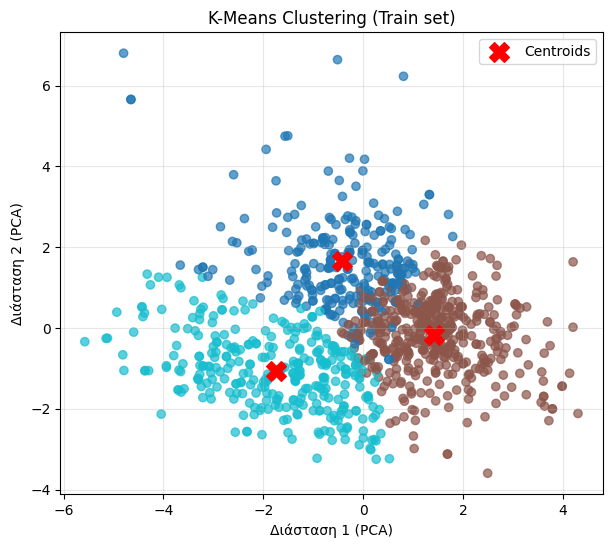

In [ ]:
# Υλοποίηση K-Means & Αξιολόγηση
def init_kmeans_centroids(X: np.ndarray, K: int, random_state: int = 42) -> np.ndarray:
    """Τυχαία αρχικοποίηση K centroids από τα σημεία του X"""
    rng = np.random.RandomState(random_state)
    indices = rng.choice(X.shape[0], size=K, replace=False)
    return X[indices]

def assign_clusters(X: np.ndarray, centroids: np.ndarray) -> np.ndarray:
    """Ανάθεση κάθε δείγματος στο κοντινότερο centroid"""
    dists = euclidean_distances(X, centroids)   # N x K
    return np.argmin(dists, axis=1)

def update_centroids(X: np.ndarray, labels: np.ndarray, K: int) -> np.ndarray:
    """Επανυπολογισμός centroids ως μέσος όρος σημείων κάθε cluster"""
    D = X.shape[1]
    centroids = np.zeros((K, D))
    for k in range(K):
        Xk = X[labels == k]
        if len(Xk) > 0:
            centroids[k] = Xk.mean(axis=0)
        else:
            # Αν κάποιο cluster είναι άδειο, επαναρχικοποίησε τυχαία
            centroids[k] = X[np.random.randint(0, X.shape[0])]
    return centroids

def kmeans(X: np.ndarray, K: int, max_iters: int = 100, tol: float = 1e-4) -> tuple:
    """Βασικός K-Means: επιστρέφει (labels, centroids)"""
    centroids = init_kmeans_centroids(X, K)
    for it in range(max_iters):
        labels = assign_clusters(X, centroids)
        new_centroids = update_centroids(X, labels, K)
        shift = np.linalg.norm(new_centroids - centroids)
        centroids = new_centroids
        if shift < tol:
            print(f"K-Means σύγκλιση σε {it+1} iterations (shift={shift:.6f})")
            break
    return labels, centroids

# Εφαρμογή K-Means

# Συνήθως χρησιμοποιούμε PCA 2D/3D για να μπορούμε να το σχεδιάσουμε
USE_PCA_FOR_KMEANS = True
if USE_PCA_FOR_KMEANS:
    X_km = Z_train   # μόνο train για clustering / ή όλο X_train_sc+X_test_sc
    y_km = y_train
    print("K-Means πάνω σε PCA features (Z_train)")
else:
    X_km = X_train_sc
    y_km = y_train
    print("K-Means πάνω σε scaled features")

K_clusters = 3

cluster_labels, centroids = kmeans(X_km, K_clusters, max_iters=100)

print("\nΚατανομή δειγμάτων ανά cluster:")
unique_c, counts_c = np.unique(cluster_labels, return_counts=True)
for c, cnt in zip(unique_c, counts_c):
    print(f"  Cluster {c}: {cnt} δείγματα")

# Σύγκριση με πραγματικές κλάσεις 
print("\nΣύγκριση cluster → πραγματικές κλάσεις:")
for c in range(K_clusters):
    idx = (cluster_labels == c)
    true_labels = y_km[idx]
    values, counts = np.unique(true_labels, return_counts=True)
    print(f"\nCluster {c}:")
    for v, cnt in zip(values, counts):
        print(f"  Κλάση {id_to_pretty[v]}: {cnt} δείγματα")

# Οπτικοποίηση σε 2D (αν έχουμε τουλάχιστον 2 διαστάσεις στο X_km) 
if X_km.shape[1] >= 2:
    plt.figure(figsize=(7,6))
    scatter = plt.scatter(X_km[:,0], X_km[:,1],
                          c=cluster_labels, cmap='tab10', alpha=0.7)
    plt.scatter(centroids[:,0], centroids[:,1],
                c='red', marker='X', s=200, label='Centroids')
    plt.title('K-Means Clustering (Train set)')
    plt.xlabel('Διάσταση 1 (PCA)' if USE_PCA_FOR_KMEANS else 'Χαρακτηριστικό 1')
    plt.ylabel('Διάσταση 2 (PCA)' if USE_PCA_FOR_KMEANS else 'Χαρακτηριστικό 2')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
